# Paddy leaf nutrient deficiency classification with ResNet-50

This notebook trains a three-class classifier from `dataset/images/`, evaluates it on a held-out test split, and visualizes its confusion matrix and per-class precision-recall curves. The data folders define the labels: `nitrogen`, `phosphorous`, and `potassium`.

The default setup uses ImageNet-pretrained ResNet-50, stratified 70/15/15 train/validation/test splits, mixed precision on CUDA, and saves the best validation checkpoint and plots under `outputs/resnet50/`. Run the cells from the project root. Install dependencies first with `pip install -r requirements.txt`.

In [ ]:
from pathlib import Path
import copy
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageFile
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, precision_recall_curve,
                             average_precision_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True
CLASSES = ("nitrogen", "phosphorous", "potassium")
DATA_DIR = Path("../dataset/images")
OUTPUT_DIR = Path("outputs/resnet50")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 3e-4
SEED = 42
NUM_WORKERS = 0  # Safe default for Windows notebooks; increase if appropriate.
FREEZE_BACKBONE = False  # Set True for faster head-only training.
USE_PRETRAINED = True  # First run may download ImageNet weights.

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


## Load and split the images

In [2]:
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths, image_labels = [], []

for label, class_name in enumerate(CLASSES):
    class_dir = DATA_DIR / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f"Expected class folder: {class_dir.resolve()}")
    
    files = sorted(p for p in class_dir.rglob("*") if p.is_file() and p.suffix.lower() in extensions)
    if len(files) < 3:
        raise ValueError(f"Need at least 3 images in {class_dir}; found {len(files)}")
    image_paths.extend(files)
    image_labels.extend([label] * len(files))
    
image_paths = np.asarray(image_paths, dtype=object)
image_labels = np.asarray(image_labels, dtype=np.int64)

print(f"Total images: {len(image_paths)}")
print({name: int((image_labels == i).sum()) for i, name in enumerate(CLASSES)})

train_idx, remainder_idx = train_test_split(
    np.arange(len(image_labels)), test_size=0.30, random_state=SEED,
    stratify=image_labels,
)

val_idx, test_idx = train_test_split(
    remainder_idx, test_size=0.50, random_state=SEED,
    stratify=image_labels[remainder_idx],
)

print(f"Split sizes — train: {len(train_idx)}, validation: {len(val_idx)}, test: {len(test_idx)}")

Total images: 1156
{'nitrogen': 440, 'phosphorous': 333, 'potassium': 383}
Split sizes — train: 809, validation: 173, test: 174


## Preprocessing and data loaders

In [3]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.12),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE + 32),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class PaddyLeafDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")
        return self.transform(image), int(self.labels[index])

pin_memory = DEVICE.type == "cuda"

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=pin_memory, persistent_workers=NUM_WORKERS > 0)

train_loader = DataLoader(PaddyLeafDataset(image_paths[train_idx], image_labels[train_idx], train_transform),
                          shuffle=True, **loader_options)
val_loader = DataLoader(PaddyLeafDataset(image_paths[val_idx], image_labels[val_idx], eval_transform),
                        **loader_options)
test_loader = DataLoader(PaddyLeafDataset(image_paths[test_idx], image_labels[test_idx], eval_transform),
                         **loader_options)

print(f"Batches — train: {len(train_loader)}, validation: {len(val_loader)}, test: {len(test_loader)}")

Batches — train: 26, validation: 6, test: 6


## Build the ResNet-50 model

In [4]:
weights = models.ResNet50_Weights.DEFAULT if USE_PRETRAINED else None

try:
    model = models.resnet50(weights=weights)
except Exception as exc:
    if not USE_PRETRAINED:
        raise
    print(f"Could not load pretrained weights ({exc}); initializing randomly instead.")
    model = models.resnet50(weights=None)

model.fc = nn.Linear(model.fc.in_features, len(CLASSES))

if FREEZE_BACKBONE:
    for name, parameter in model.named_parameters():
        parameter.requires_grad = name.startswith("fc.")
        
model = model.to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                              lr=LEARNING_RATE, weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Trainable parameters: 23,514,179


## Train and select the best validation checkpoint

In [5]:
def run_epoch(loader, training=False):
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    for images, targets in tqdm(loader, leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                                enabled=DEVICE.type == "cuda"):
                logits = model(images)
                loss = criterion(logits, targets)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total_loss += loss.item() * targets.size(0)
        correct += (logits.argmax(1) == targets).sum().item()
        count += targets.size(0)
    return total_loss / count, correct / count

history = {"train_loss": [], "validation_loss": [],
           "train_accuracy": [], "validation_accuracy": []}

best_loss, best_epoch, best_state = float("inf"), 0, None
start_time = time.time()

for epoch in range(EPOCHS):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    val_loss, val_accuracy = run_epoch(val_loader)
    scheduler.step()
    history["train_loss"].append(train_loss)
    history["validation_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_accuracy"].append(val_accuracy)

    print(f"Epoch {epoch + 1:02}/{EPOCHS}: train loss={train_loss:.4f}, acc={train_accuracy:.3f} | "
          f"val loss={val_loss:.4f}, acc={val_accuracy:.3f}")
    
    if val_loss < best_loss:
        best_loss, best_epoch = val_loss, epoch + 1
        best_state = copy.deepcopy(model.state_dict())
        
model.load_state_dict(best_state)
print(f"Best epoch: {best_epoch}; training time: {(time.time() - start_time) / 60:.1f} min")

  0%|          | 0/26 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 01/20: train loss=0.6926, acc=0.732 | val loss=0.3415, acc=0.890


  0%|          | 0/26 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

...

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 19/20: train loss=0.0170, acc=0.995 | val loss=0.2050, acc=0.936


  0%|          | 0/26 [00:00<?, ?it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

Epoch 20/20: train loss=0.0108, acc=0.998 | val loss=0.2113, acc=0.936
Best epoch: 4; training time: 8.4 min


## Evaluate on the held-out test split

In [6]:
@torch.inference_mode()
def predict(loader):
    model.eval()
    truth, probabilities = [], []
    for images, targets in tqdm(loader, desc="Test", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                            enabled=DEVICE.type == "cuda"):
            probs = model(images).softmax(dim=1)
        truth.extend(targets.numpy().tolist())
        probabilities.extend(probs.float().cpu().numpy())
    return np.asarray(truth), np.asarray(probabilities)

y_true, y_prob = predict(test_loader)
y_pred = y_prob.argmax(axis=1)
test_accuracy = float((y_true == y_pred).mean())

print(f"Held-out test accuracy: {test_accuracy:.3f}")
print(classification_report(y_true, y_pred, labels=range(len(CLASSES)),
                            target_names=CLASSES, zero_division=0))

Test:   0%|          | 0/6 [00:00<?, ?it/s]

Held-out test accuracy: 0.914
              precision    recall  f1-score   support

    nitrogen       0.94      0.95      0.95        66
 phosphorous       0.88      0.88      0.88        50
   potassium       0.91      0.90      0.90        58

    accuracy                           0.91       174
   macro avg       0.91      0.91      0.91       174
weighted avg       0.91      0.91      0.91       174



## Confusion matrix and precision-recall curves

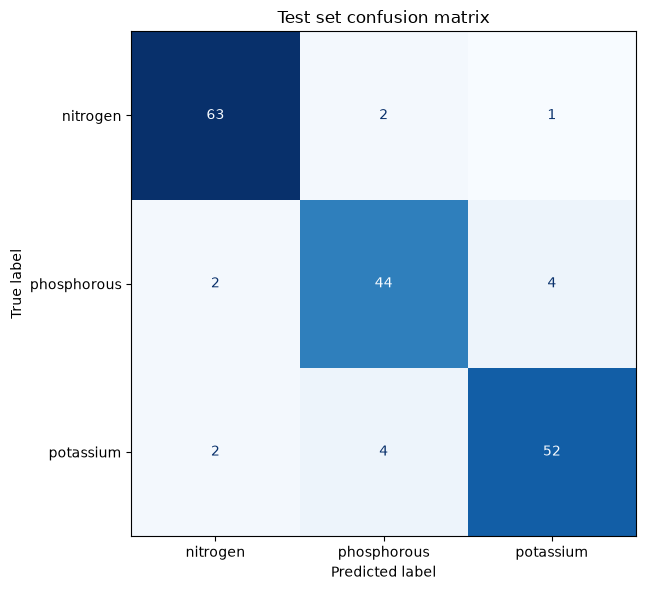

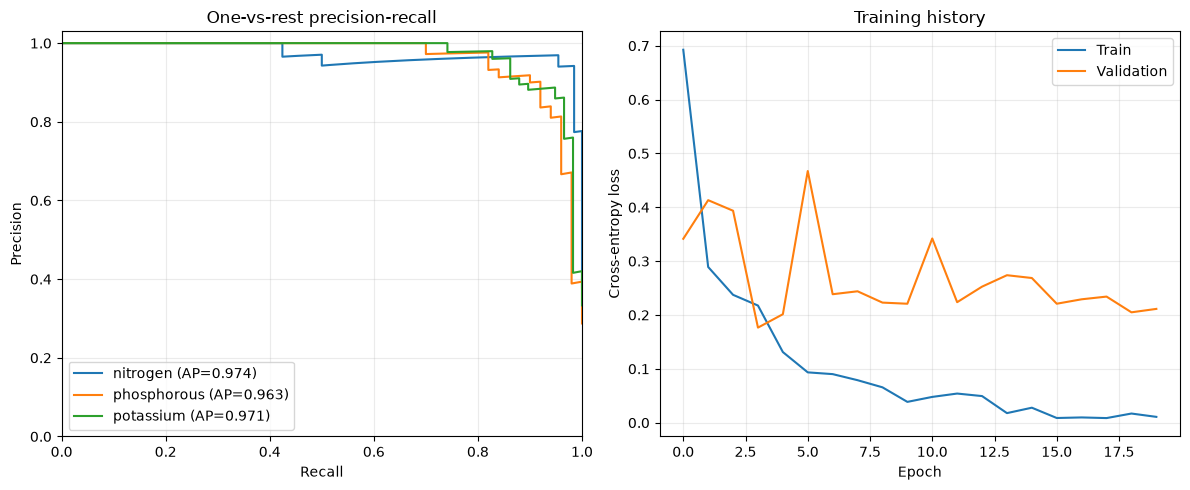

In [7]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Test set confusion matrix")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180)
plt.show()

binary_truth = label_binarize(y_true, classes=range(len(CLASSES)))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, class_name in enumerate(CLASSES):
    precision, recall, _ = precision_recall_curve(binary_truth[:, i], y_prob[:, i])
    ap = average_precision_score(binary_truth[:, i], y_prob[:, i])
    axes[0].plot(recall, precision, label=f"{class_name} (AP={ap:.3f})")
axes[0].set(xlabel="Recall", ylabel="Precision", title="One-vs-rest precision-recall")
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1.03); axes[0].grid(alpha=0.25)
axes[0].legend()
axes[1].plot(history["train_loss"], label="Train")
axes[1].plot(history["validation_loss"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Training history")
axes[1].grid(alpha=0.25); axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "precision_recall_and_training.png", dpi=180)
plt.show()

## Save model and test metrics

In [8]:
checkpoint = {
    "state_dict": model.state_dict(), "classes": list(CLASSES),
    "image_size": IMAGE_SIZE, "mean": IMAGENET_MEAN, "std": IMAGENET_STD,
    "architecture": "resnet50", "best_epoch": best_epoch,
}
torch.save(checkpoint, OUTPUT_DIR / "resnet50_paddy.pth")
metrics = {
    "classes": list(CLASSES), "samples": int(len(image_paths)),
    "split_sizes": {"train": int(len(train_idx)), "validation": int(len(val_idx)), "test": int(len(test_idx))},
    "best_epoch": int(best_epoch), "test_accuracy": test_accuracy,
    "confusion_matrix": cm.tolist(),
    "classification_report": classification_report(
        y_true, y_pred, labels=range(len(CLASSES)), target_names=CLASSES,
        output_dict=True, zero_division=0),
    "history": history,
}

(OUTPUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(f"Saved checkpoint and results to {OUTPUT_DIR.resolve()}")

Saved checkpoint and results to D:\Finaly Year Research Project\Project\notebooks\outputs\resnet50
